# Wallet relationship analysis

**Not another model.** This notebook answers: *which wallet relationships does the TGNN
identify, and what do those relationships actually look like in the underlying trading data?*

**Design choices, and why:**
- Ranks by the model's **margin score** (positive-pair score minus a random-negative baseline
  for the same wallet at that moment), not by static embedding cosine similarity. We already
  tested cosine similarity against real behavior and found it weak (rho=0.107) — margin score
  is the thing the model was actually trained and validated on (hard-negative ROC-AUC 0.85), so
  it's the right quantity to rank by.
- Uses **deduplicated** `temporal_edges` throughout (the crowd-timestamp trade-fragment bug is fixed).
- Requires a **minimum number of real events** per pair before it's eligible to be called a
  "relationship" — we learned the hard way that degree-1/event-1 pairs are dominated by artifacts.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

## 1. Load — event-level scores, wallet features, and the deduplicated trade record

In [19]:
event_scores = pd.read_parquet("../data/processed/event_relationship_scores.parquet")
temporal_edges = pd.read_parquet("../data/processed/temporal_edges.parquet")
wallet_features = pd.read_parquet("../data/processed/wallet_features.parquet")

print("Event scores:", event_scores.shape)
print("Temporal edges (pre-dedup):", temporal_edges.shape)

Event scores: (103779, 6)
Temporal edges (pre-dedup): (103779, 17)


In [20]:
# Deduplicate the trade-fragment artifact (same fix as tgnn_v2.ipynb)
temporal_edges = temporal_edges.copy()
temporal_edges["pair_key"] = temporal_edges.apply(
    lambda r: tuple(sorted((r["source"], r["target"]))), axis=1
)
temporal_edges = (
    temporal_edges
    .sort_values("time_diff")
    .drop_duplicates(subset=["pair_key", "timestamp"], keep="first")
    .drop(columns="pair_key")
    .reset_index(drop=True)
)
print("After dedup:", len(temporal_edges))

# Same dedup applied to event_scores so the two line up on the same event set
event_scores["pair_key"] = event_scores.apply(
    lambda r: tuple(sorted((r["source"], r["target"]))), axis=1
)
event_scores = (
    event_scores
    .merge(temporal_edges[["source", "target", "timestamp"]].drop_duplicates(),
           on=["source", "target", "timestamp"], how="inner")
    .drop(columns="pair_key")
)
print("Event scores after aligning to dedup:", len(event_scores))

After dedup: 51356
Event scores after aligning to dedup: 99141


## 2. Aggregate to pair level

`margin` is the key column: how much more likely the model thought this specific interaction
was, compared to a random alternative for the same wallet at that moment. Averaging it across
all of a pair's real events gives a relationship strength that's already controlled for
"this wallet just scores high with everyone."

In [21]:
event_scores["pair_key"] = event_scores.apply(
    lambda r: tuple(sorted((r["source"], r["target"]))), axis=1
)

pair_scores = (
    event_scores
    .groupby("pair_key")
    .agg(
        n_events=("margin", "size"),
        mean_margin=("margin", "mean"),
        mean_positive_score=("positive_score", "mean"),
        first_scored_event=("timestamp", "min"),
        last_scored_event=("timestamp", "max"),
    )
    .reset_index()
)

MIN_EVENTS = 3   # learned the hard way — below this, findings are noise/artifact-prone
eligible_pairs = pair_scores[pair_scores["n_events"] >= MIN_EVENTS].copy()

print(f"{len(pair_scores)} total pairs scored, {len(eligible_pairs)} with >= {MIN_EVENTS} events")

28102 total pairs scored, 6423 with >= 3 events


## 3. Rank — strongest relationships by margin score

In [22]:
top_relationships = eligible_pairs.sort_values("mean_margin", ascending=False).head(30).copy()
top_relationships["wallet_a"] = top_relationships["pair_key"].apply(lambda p: p[0])
top_relationships["wallet_b"] = top_relationships["pair_key"].apply(lambda p: p[1])
top_relationships[["wallet_a", "wallet_b", "n_events", "mean_margin", "mean_positive_score"]]

,wallet_a,wallet_b,n_events,mean_margin,mean_positive_score
14187,0x520ba070df2b17358f8ebeb66a792492e1c6c1a2,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,3,11.581609,9.728792
16883,0x6a31cce9012132bdfa9ec46f434ee8e040eadd3d,0xa8c63f775ddbbe66b56614191747def3021444e8,3,11.332870,9.844679
10771,0x3cec9fbe41e58dd77809fee6213029dd2a679b2e,0xab19716584931d81cd9e7763402673a64baa4876,3,11.023834,9.684994
15442,0x5c051189f9c0eae99ed0b2ff3d8ff14bf4484e22,0x849ccb5907938ce8be18ed5dbf583288e2da4009,4,10.945514,9.970192
15456,0x5c5e54a315cc2d370ba5a9dbccb48d8b9f7f1354,0xb308f01fac3e2a9d8c7ba579c615d236261f9a32,3,10.906583,9.951973
10964,0x3eae57986be5e0ca435102ffe1f14206ffa2e2ed,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,4,10.882351,9.870505
24565,0xab19716584931d81cd9e7763402673a64baa4876,0xf667c1e9b7436a01f0352aa7cbd589c347a337f2,3,10.795786,9.925571
15455,0x5c5e54a315cc2d370ba5a9dbccb48d8b9f7f1354,0xae5839b89d47738616264276ac1f0d77f936e5c5,3,10.776604,9.984675
26883,0xc9867009f4b998dc2342750c8eaaaa97bd9ada9a,0xcc2982e3fbbcaf9af9fa373fa3ae392fd9457774,13,10.695449,9.913255
26885,0xc9867009f4b998dc2342750c8eaaaa97bd9ada9a,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,7,10.668739,9.930462


## 4. Look back at the actual trading history for each top relationship

This is the ground-truth check — pull every real trade-pair event for each top-ranked
relationship and describe it in plain behavioral terms.

In [23]:
def pair_full_history(wallet_a, wallet_b, edges):
    mask = (
        ((edges["source"] == wallet_a) & (edges["target"] == wallet_b)) |
        ((edges["source"] == wallet_b) & (edges["target"] == wallet_a))
    )
    return edges[mask].sort_values("timestamp")


profiles = []
for _, row in top_relationships.iterrows():
    hist = pair_full_history(row["wallet_a"], row["wallet_b"], temporal_edges)
    if len(hist) == 0:
        continue

    span_days = (hist["timestamp"].max() - hist["timestamp"].min()).total_seconds() / 86400

    profiles.append({
        "wallet_a": row["wallet_a"], "wallet_b": row["wallet_b"],
        "mean_margin": row["mean_margin"],
        "n_real_events": len(hist),
        "distinct_timestamps": hist["timestamp"].nunique(),
        "span_days": span_days,
        "pct_same_side": hist["same_side"].mean(),
        "pct_same_outcome": hist["same_outcome"].mean(),
        "median_time_diff_s": hist["time_diff"].median(),
        "median_price_diff": hist["price_diff"].median(),
        "median_size_ratio": hist["size_ratio"].median(),
    })

profiles_df = pd.DataFrame(profiles)
profiles_df

,wallet_a,wallet_b,mean_margin,n_real_events,distinct_timestamps,span_days,pct_same_side,pct_same_outcome,median_time_diff_s,median_price_diff,median_size_ratio
0,0x520ba070df2b17358f8ebeb66a792492e1c6c1a2,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,11.581609,2,2,1.976597,0.500000,1.0,22.0,5.000000e-03,0.506031
1,0x6a31cce9012132bdfa9ec46f434ee8e040eadd3d,0xa8c63f775ddbbe66b56614191747def3021444e8,11.332870,3,3,0.123472,0.000000,1.0,156.0,1.000000e-02,0.395238
2,0x3cec9fbe41e58dd77809fee6213029dd2a679b2e,0xab19716584931d81cd9e7763402673a64baa4876,11.023834,3,3,0.250752,0.666667,0.0,232.0,8.200000e-01,0.701136
3,0x5c051189f9c0eae99ed0b2ff3d8ff14bf4484e22,0x849ccb5907938ce8be18ed5dbf583288e2da4009,10.945514,1,1,0.000000,0.000000,1.0,30.0,0.000000e+00,0.205741
4,0x5c5e54a315cc2d370ba5a9dbccb48d8b9f7f1354,0xb308f01fac3e2a9d8c7ba579c615d236261f9a32,10.906583,2,2,0.000347,1.000000,1.0,15.0,0.000000e+00,0.465316
5,0x3eae57986be5e0ca435102ffe1f14206ffa2e2ed,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,10.882351,4,4,0.305486,1.000000,0.0,107.5,8.300000e-01,0.669119
6,0xab19716584931d81cd9e7763402673a64baa4876,0xf667c1e9b7436a01f0352aa7cbd589c347a337f2,10.795786,2,2,0.003449,1.000000,0.0,149.0,8.200000e-01,0.704511
7,0x5c5e54a315cc2d370ba5a9dbccb48d8b9f7f1354,0xae5839b89d47738616264276ac1f0d77f936e5c5,10.776604,2,2,0.000347,1.000000,0.0,36.0,8.400000e-01,0.148543
8,0xc9867009f4b998dc2342750c8eaaaa97bd9ada9a,0xcc2982e3fbbcaf9af9fa373fa3ae392fd9457774,10.695449,13,13,0.504815,1.000000,0.0,0.0,8.200000e-01,1.000000
9,0xc9867009f4b998dc2342750c8eaaaa97bd9ada9a,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,10.668739,7,7,0.379063,1.000000,0.0,0.0,8.200000e-01,1.000000


## 5. Analyze *why* — classify each relationship's shape

Two independent dimensions describe most of what we've seen across this whole project:
- **Persistence**: one-off coincidence vs. recurring over a long span (`span_days`, `distinct_timestamps`)
- **Tightness**: loosely timed/priced vs. near-simultaneous, near-identical price (`median_time_diff_s`, `median_price_diff`)

Combining them gives interpretable archetypes rather than an arbitrary cluster count.

In [24]:
def classify_relationship(row):
    persistent = row["span_days"] > 7 and row["distinct_timestamps"] >= 3
    tight = row["median_time_diff_s"] <= 5 and row["median_price_diff"] <= 0.01

    if persistent and tight:
        return "Persistent tight-coupling (strongest candidate for same-actor/coordination)"
    elif persistent and not tight:
        return "Persistent loose relationship (recurring, but not tightly synchronized)"
    elif not persistent and tight:
        return "One-off tight match (possibly a single coincidental crowded moment — inspect closely)"
    else:
        return "One-off loose match (weak evidence)"


profiles_df["relationship_type"] = profiles_df.apply(classify_relationship, axis=1)
profiles_df["relationship_type"].value_counts()

relationship_type
One-off loose match (weak evidence)                                                      24
One-off tight match (possibly a single coincidental crowded moment — inspect closely)     6
Name: count, dtype: int64

In [25]:
profiles_df.sort_values("mean_margin", ascending=False)[
    ["wallet_a", "wallet_b", "mean_margin", "relationship_type",
     "n_real_events", "span_days", "median_time_diff_s", "median_price_diff",
     "pct_same_side", "pct_same_outcome"]
]

,wallet_a,wallet_b,mean_margin,relationship_type,n_real_events,span_days,median_time_diff_s,median_price_diff,pct_same_side,pct_same_outcome
0,0x520ba070df2b17358f8ebeb66a792492e1c6c1a2,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,11.581609,One-off loose match (weak evidence),2,1.976597,22.0,5.000000e-03,0.500000,1.0
1,0x6a31cce9012132bdfa9ec46f434ee8e040eadd3d,0xa8c63f775ddbbe66b56614191747def3021444e8,11.332870,One-off loose match (weak evidence),3,0.123472,156.0,1.000000e-02,0.000000,1.0
2,0x3cec9fbe41e58dd77809fee6213029dd2a679b2e,0xab19716584931d81cd9e7763402673a64baa4876,11.023834,One-off loose match (weak evidence),3,0.250752,232.0,8.200000e-01,0.666667,0.0
3,0x5c051189f9c0eae99ed0b2ff3d8ff14bf4484e22,0x849ccb5907938ce8be18ed5dbf583288e2da4009,10.945514,One-off loose match (weak evidence),1,0.000000,30.0,0.000000e+00,0.000000,1.0
4,0x5c5e54a315cc2d370ba5a9dbccb48d8b9f7f1354,0xb308f01fac3e2a9d8c7ba579c615d236261f9a32,10.906583,One-off loose match (weak evidence),2,0.000347,15.0,0.000000e+00,1.000000,1.0
5,0x3eae57986be5e0ca435102ffe1f14206ffa2e2ed,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,10.882351,One-off loose match (weak evidence),4,0.305486,107.5,8.300000e-01,1.000000,0.0
6,0xab19716584931d81cd9e7763402673a64baa4876,0xf667c1e9b7436a01f0352aa7cbd589c347a337f2,10.795786,One-off loose match (weak evidence),2,0.003449,149.0,8.200000e-01,1.000000,0.0
7,0x5c5e54a315cc2d370ba5a9dbccb48d8b9f7f1354,0xae5839b89d47738616264276ac1f0d77f936e5c5,10.776604,One-off loose match (weak evidence),2,0.000347,36.0,8.400000e-01,1.000000,0.0
8,0xc9867009f4b998dc2342750c8eaaaa97bd9ada9a,0xcc2982e3fbbcaf9af9fa373fa3ae392fd9457774,10.695449,One-off loose match (weak evidence),13,0.504815,0.0,8.200000e-01,1.000000,0.0
9,0xc9867009f4b998dc2342750c8eaaaa97bd9ada9a,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,10.668739,One-off loose match (weak evidence),7,0.379063,0.0,8.200000e-01,1.000000,0.0


## 6. Identify recurring patterns across ALL eligible relationships (not just the top 30)

The top 30 is a useful spot-check, but the real "recurring pattern" question needs the
full eligible population — otherwise you're just describing whichever pairs happened to
rank highest, not what patterns actually recur.

In [26]:
all_profiles = []
for _, row in eligible_pairs.iterrows():
    wallet_a, wallet_b = row["pair_key"]
    hist = pair_full_history(wallet_a, wallet_b, temporal_edges)
    if len(hist) == 0:
        continue
    span_days = (hist["timestamp"].max() - hist["timestamp"].min()).total_seconds() / 86400
    all_profiles.append({
        "wallet_a": wallet_a, "wallet_b": wallet_b,
        "mean_margin": row["mean_margin"], "n_real_events": len(hist),
        "distinct_timestamps": hist["timestamp"].nunique(), "span_days": span_days,
        "median_time_diff_s": hist["time_diff"].median(),
        "median_price_diff": hist["price_diff"].median(),
        "pct_same_side": hist["same_side"].mean(),
        "pct_same_outcome": hist["same_outcome"].mean(),
    })

all_profiles_df = pd.DataFrame(all_profiles)
all_profiles_df["relationship_type"] = all_profiles_df.apply(classify_relationship, axis=1)

print(f"{len(all_profiles_df)} eligible relationships analyzed\n")
print(all_profiles_df["relationship_type"].value_counts())
print("\nAs % of total:")
print((all_profiles_df["relationship_type"].value_counts(normalize=True) * 100).round(1))

6423 eligible relationships analyzed

relationship_type
One-off loose match (weak evidence)                                                      3952
Persistent loose relationship (recurring, but not tightly synchronized)                  1156
One-off tight match (possibly a single coincidental crowded moment — inspect closely)     836
Persistent tight-coupling (strongest candidate for same-actor/coordination)               479
Name: count, dtype: int64

As % of total:
relationship_type
One-off loose match (weak evidence)                                                      61.5
Persistent loose relationship (recurring, but not tightly synchronized)                  18.0
One-off tight match (possibly a single coincidental crowded moment — inspect closely)    13.0
Persistent tight-coupling (strongest candidate for same-actor/coordination)               7.5
Name: proportion, dtype: float64


In [27]:
# Does the model's own margin score actually rank the "strongest" archetype highest?
# This is a sanity check on whether ranking-by-margin is doing something sensible.
all_profiles_df.groupby("relationship_type")["mean_margin"].describe()[["count", "mean", "50%"]]

,count,mean,50%
relationship_type,,,
One-off loose match (weak evidence),3952.0,3.272624,2.301031
One-off tight match (possibly a single coincidental crowded moment — inspect closely),836.0,3.366080,2.511920
"Persistent loose relationship (recurring, but not tightly synchronized)",1156.0,3.060604,2.734187
Persistent tight-coupling (strongest candidate for same-actor/coordination),479.0,2.972267,2.590460


## 7. Visualize the pattern landscape

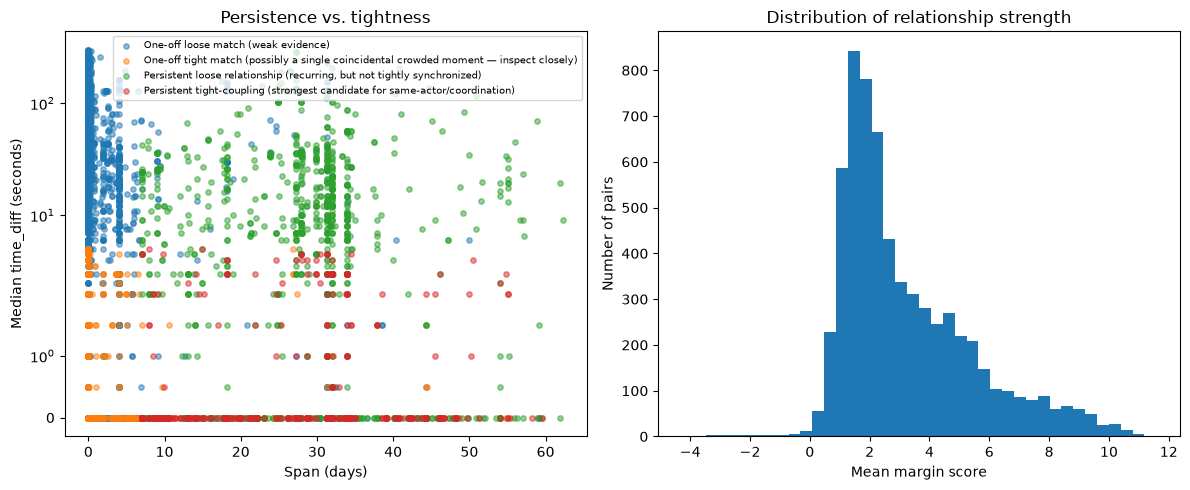

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for label, group in all_profiles_df.groupby("relationship_type"):
    axes[0].scatter(group["span_days"], group["median_time_diff_s"], s=15, alpha=0.5, label=label)

axes[0].set_xlabel("Span (days)")
axes[0].set_ylabel("Median time_diff (seconds)")
axes[0].set_yscale("symlog")
axes[0].set_title("Persistence vs. tightness")
axes[0].legend(fontsize=7, loc="upper right")

axes[1].hist(all_profiles_df["mean_margin"], bins=40)
axes[1].set_xlabel("Mean margin score")
axes[1].set_ylabel("Number of pairs")
axes[1].set_title("Distribution of relationship strength")

plt.tight_layout()
plt.show()

## 8. Summary

In [29]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Total scored pairs: {len(pair_scores)}")
print(f"Eligible (>= {MIN_EVENTS} real events): {len(eligible_pairs)}")
print(f"Analyzed with full trading history: {len(all_profiles_df)}")
print()
print("Relationship type breakdown:")
print(all_profiles_df["relationship_type"].value_counts())
print()
print("Top 5 strongest relationships (by model margin score):")
print(top_relationships[["wallet_a", "wallet_b", "n_events", "mean_margin"]].head(5).to_string(index=False))

SUMMARY
Total scored pairs: 28102
Eligible (>= 3 real events): 6423
Analyzed with full trading history: 6423

Relationship type breakdown:
relationship_type
One-off loose match (weak evidence)                                                      3952
Persistent loose relationship (recurring, but not tightly synchronized)                  1156
One-off tight match (possibly a single coincidental crowded moment — inspect closely)     836
Persistent tight-coupling (strongest candidate for same-actor/coordination)               479
Name: count, dtype: int64

Top 5 strongest relationships (by model margin score):
                                  wallet_a                                   wallet_b  n_events  mean_margin
0x520ba070df2b17358f8ebeb66a792492e1c6c1a2 0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8         3    11.581609
0x6a31cce9012132bdfa9ec46f434ee8e040eadd3d 0xa8c63f775ddbbe66b56614191747def3021444e8         3    11.332870
0x3cec9fbe41e58dd77809fee6213029dd2a679b2e 0xab19716584931

In [30]:
bins = [2, 3, 5, 10, 20, eligible_pairs["n_events"].max()]
eligible_pairs.groupby(
    pd.cut(eligible_pairs["n_events"], bins=bins)
)["mean_margin"].describe()[["count", "mean", "50%"]]

,count,mean,50%
n_events,,,
"(2, 3]",1936.0,3.282705,2.577117
"(3, 5]",1671.0,3.283873,2.482027
"(5, 10]",1285.0,3.239538,2.499620
"(10, 20]",898.0,3.092659,2.335015
"(20, 1185]",633.0,3.043512,2.241502


In [31]:
eligible_pairs["n_events"].describe()
eligible_pairs["n_events"].value_counts().sort_index().head(10)

n_events
3     1936
4     1154
5      517
6      476
7      194
8      236
9      186
10     193
11     130
12     145
Name: count, dtype: int64

In [32]:
top_wallet_pairs = list(zip(top_relationships["wallet_a"], top_relationships["wallet_b"]))

for wallet_a, wallet_b in top_wallet_pairs[:5]:
    mask = (
        ((event_scores["source"] == wallet_a) & (event_scores["target"] == wallet_b)) |
        ((event_scores["source"] == wallet_b) & (event_scores["target"] == wallet_a))
    )
    scores = event_scores.loc[mask, "margin"].values
    print(f"{wallet_a[:10]}.. <-> {wallet_b[:10]}..  "
          f"events={len(scores)}  margins={np.round(scores, 2)}  "
          f"mean={scores.mean():.2f}  std={scores.std():.2f}")

0x520ba070.. <-> 0xa58d4f27..  events=3  margins=[10.75 12.48 11.52]  mean=11.58  std=0.71
0x6a31cce9.. <-> 0xa8c63f77..  events=3  margins=[11.44 10.93 11.63]  mean=11.33  std=0.30
0x3cec9fbe.. <-> 0xab197165..  events=3  margins=[10.99 11.55 10.53]  mean=11.02  std=0.42
0x5c051189.. <-> 0x849ccb59..  events=4  margins=[10.17 12.26 11.33 10.02]  mean=10.95  std=0.91
0x5c5e54a3.. <-> 0xb308f01f..  events=3  margins=[11.2  11.1  10.42]  mean=10.91  std=0.35


In [33]:
persistent_tight = all_profiles_df[
    all_profiles_df["relationship_type"] == "Persistent tight-coupling (strongest candidate for same-actor/coordination)"
].sort_values("mean_margin", ascending=False)

persistent_tight.to_parquet("../data/processed/candidate_relationships.parquet")
print(f"Exported {len(persistent_tight)} candidate relationships")

Exported 479 candidate relationships


In [34]:
export_df = eligible_pairs.copy()
export_df["wallet_a"] = export_df["pair_key"].apply(lambda p: p[0])
export_df["wallet_b"] = export_df["pair_key"].apply(lambda p: p[1])
export_df[["wallet_a", "wallet_b", "n_events", "mean_margin"]].to_parquet(
    "../data/processed/pair_relationship_scores.parquet"
)